# 02. TWFE推定

Y_it = β log(MW_it) + α_i + γ_t + ε_it

月次パネルでのTwo-Way Fixed Effects推定。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
import japanize_matplotlib
from pathlib import Path
from linearmodels.panel import PanelOLS

OUT = Path('../output')
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'figures').mkdir(exist_ok=True)

df = pd.read_csv('../data/analysis_sample.csv')
df['yearmonth'] = df['year'] * 100 + df['month']
df = df.set_index(['pref_code', 'yearmonth'])
print(f'Shape: {df.shape}')

Shape: (6909, 20)


## 1. ベースライン TWFE

In [2]:
outcomes = {
    'log_wage_total': 'log(現金給与総額)',
    'log_wage_scheduled': 'log(所定内給与)',
    'hours_total': '総実労働時間',
    'log_hours_total': 'log(総実労働時間)',
    'hours_scheduled': '所定内労働時間',
    'hours_overtime': '所定外労働時間',
    'log_workers': 'log(常用労働者数)',
}

results = []
for yvar, label in outcomes.items():
    mod = PanelOLS(df[yvar], df[['log_mw']],
                   entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    results.append({
        'outcome': label,
        'beta': res.params['log_mw'],
        'se': res.std_errors['log_mw'],
        't': res.tstats['log_mw'],
        'p': res.pvalues['log_mw'],
        'N': res.nobs,
        'R2_within': res.rsquared_within,
    })

tab = pd.DataFrame(results)
tab['sig'] = tab['p'].apply(lambda p: '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else '')
tab['beta_se'] = tab.apply(lambda r: f"{r['beta']:.4f} ({r['se']:.4f}){r['sig']}", axis=1)

print('=== TWFE ベースライン: Y_it = β log(MW_it) + α_i + γ_t + ε_it ===')
print('SE: 都道府県クラスター')
print()
print(tab[['outcome', 'beta_se', 'N', 'R2_within']].to_string(index=False))

=== TWFE ベースライン: Y_it = β log(MW_it) + α_i + γ_t + ε_it ===
SE: 都道府県クラスター

    outcome               beta_se    N  R2_within
log(現金給与総額)      -0.0117 (0.1471) 6909  -0.001607
 log(所定内給与)      -0.0204 (0.1383) 6909  -0.107609
     総実労働時間  -31.0660 (12.3606)** 6909   0.423628
log(総実労働時間)     -0.1600 (0.0914)* 6909   0.364184
    所定内労働時間 -29.0676 (10.2147)*** 6909   0.412558
    所定外労働時間      -1.9984 (3.6525) 6909   0.170488
log(常用労働者数)      -0.3915 (0.3243) 6909  -2.013204


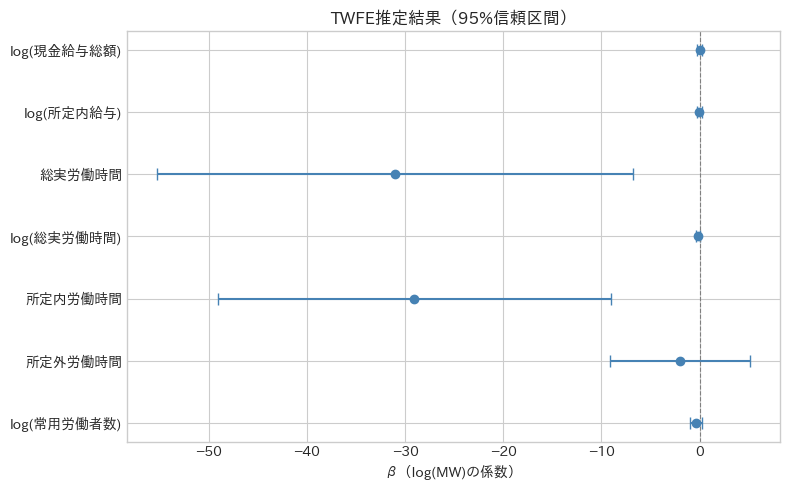

In [3]:
# 係数プロット
fig, ax = plt.subplots(figsize=(8, 5))
tab_plot = pd.DataFrame(results)
y_pos = range(len(tab_plot))

ax.errorbar(tab_plot['beta'], y_pos,
            xerr=1.96 * tab_plot['se'],
            fmt='o', color='steelblue', capsize=4, markersize=6)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_yticks(list(y_pos))
ax.set_yticklabels([outcomes[k] for k in outcomes.keys()])
ax.set_xlabel('β（log(MW)の係数）')
ax.set_title('TWFE推定結果（95%信頼区間）')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(OUT / 'figures' / '02_twfe_coef_plot.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. 主要アウトカムの詳細出力

In [4]:
# 所定内給与と総実労働時間の詳細
for yvar, label in [('log_wage_scheduled', 'log(所定内給与)'),
                     ('log_hours_total', 'log(総実労働時間)')]:
    mod = PanelOLS(df[yvar], df[['log_mw']],
                   entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    print(f'\n{"="*60}')
    print(f'アウトカム: {label}')
    print(f'{"="*60}')
    print(res.summary)


アウトカム: log(所定内給与)
                          PanelOLS Estimation Summary                           
Dep. Variable:     log_wage_scheduled   R-squared:                     8.205e-05
Estimator:                   PanelOLS   R-squared (Between):             -0.0223
No. Observations:                6909   R-squared (Within):              -0.1076
Date:                Sat, Sep 19 2026   R-squared (Overall):             -0.0223
Time:                        18:05:54   Log-likelihood                 1.777e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      0.5510
Entities:                          47   P-value                           0.4579
Avg Obs:                       147.00   Distribution:                  F(1,6715)
Min Obs:                       147.00                                           
Max Obs:                       147.00   F-statistic (robust):             0.0217
         

## 3. 頑健性チェック

In [5]:
# 頑健性チェック: コロナ除外、FE構造変更
df_orig = df.copy()
df_orig['year'] = df_orig.index.get_level_values('yearmonth') // 100
df_orig['month'] = df_orig.index.get_level_values('yearmonth') % 100

# サンプルバリエーション
samples = {
    'ベースライン': df_orig,
    'コロナ除外(2020-21)': df_orig[~df_orig['year'].isin([2020, 2021])],
    '2013-2018のみ': df_orig[df_orig['year'] <= 2018],
    '2020-2025のみ': df_orig[df_orig['year'] >= 2020],
}

key_outcomes = ['log_wage_scheduled', 'log_hours_total', 'hours_overtime']
key_labels = ['log(所定内給与)', 'log(総実労働時間)', '所定外労働時間']

robust_results = []
for sname, sdf in samples.items():
    for yvar, label in zip(key_outcomes, key_labels):
        try:
            mod = PanelOLS(sdf[yvar], sdf[['log_mw']],
                           entity_effects=True, time_effects=True)
            res = mod.fit(cov_type='clustered', cluster_entity=True)
            robust_results.append({
                'sample': sname,
                'outcome': label,
                'beta': res.params['log_mw'],
                'se': res.std_errors['log_mw'],
                'p': res.pvalues['log_mw'],
                'N': res.nobs,
            })
        except Exception as e:
            robust_results.append({
                'sample': sname, 'outcome': label,
                'beta': np.nan, 'se': np.nan, 'p': np.nan, 'N': 0,
            })

rtab = pd.DataFrame(robust_results)
rtab['sig'] = rtab['p'].apply(lambda p: '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else '' if not np.isnan(p) else '')
rtab['coef'] = rtab.apply(lambda r: f"{r['beta']:.4f} ({r['se']:.4f}){r['sig']}" if not np.isnan(r['beta']) else 'N/A', axis=1)

# ピボットテーブル
pivot = rtab.pivot(index='sample', columns='outcome', values='coef')
pivot = pivot.reindex(['ベースライン', 'コロナ除外(2020-21)', '2013-2018のみ', '2020-2025のみ'])

print('=== 頑健性チェック ===')
print(pivot.to_string())

=== 頑健性チェック ===
outcome               log(所定内給与)         log(総実労働時間)            所定外労働時間
sample                                                                 
ベースライン          -0.0204 (0.1383)   -0.1600 (0.0914)*   -1.9984 (3.6525)
コロナ除外(2020-21)  -0.0250 (0.1396)   -0.1507 (0.0909)*   -1.0467 (3.6037)
2013-2018のみ     -0.7301 (0.4845)     0.2214 (0.2147)  17.5823 (20.0602)
2020-2025のみ      0.0914 (0.1058)  -0.1932 (0.0965)**  -7.0646 (3.6153)*


In [6]:
# 都道府県固有線形トレンド
df_trend = df_orig.copy()
# 時間トレンド変数
ym_vals = sorted(df_trend.index.get_level_values('yearmonth').unique())
ym_to_t = {ym: i for i, ym in enumerate(ym_vals)}
df_trend['t'] = df_trend.index.get_level_values('yearmonth').map(ym_to_t)

# 都道府県ダミー × t
pref_codes = df_trend.index.get_level_values('pref_code')
for p in sorted(pref_codes.unique())[1:]:  # 1つ落とす
    df_trend[f'pref{p}_t'] = (pref_codes == p).astype(int) * df_trend['t']

trend_cols = [c for c in df_trend.columns if c.startswith('pref') and c.endswith('_t')]

print('=== 都道府県固有線形トレンド追加 ===')
trend_results = []
for yvar, label in zip(key_outcomes, key_labels):
    # トレンドなし（ベースライン再掲）
    mod0 = PanelOLS(df_trend[yvar], df_trend[['log_mw']],
                    entity_effects=True, time_effects=True)
    res0 = mod0.fit(cov_type='clustered', cluster_entity=True)
    
    # トレンドあり
    mod1 = PanelOLS(df_trend[yvar], df_trend[['log_mw'] + trend_cols],
                    entity_effects=True, time_effects=True)
    res1 = mod1.fit(cov_type='clustered', cluster_entity=True)
    
    trend_results.append({
        'outcome': label,
        'baseline': f"{res0.params['log_mw']:.4f} ({res0.std_errors['log_mw']:.4f})",
        'with_trend': f"{res1.params['log_mw']:.4f} ({res1.std_errors['log_mw']:.4f})",
    })

ttab = pd.DataFrame(trend_results)
print(ttab.to_string(index=False))

=== 都道府県固有線形トレンド追加 ===


    outcome         baseline       with_trend
 log(所定内給与) -0.0204 (0.1383)  0.0929 (0.1161)
log(総実労働時間) -0.1600 (0.0914) -0.0644 (0.0795)
    所定外労働時間 -1.9984 (3.6525) -7.9163 (3.9317)


## 4. FE構造の比較

In [7]:
# 年×月 FE vs 年FE + 月FE
df_fe = df_orig.copy()

# 月ダミー（1月を基準）
for m in range(2, 13):
    df_fe[f'month_{m}'] = (df_fe['month'] == m).astype(int)
month_dummies = [f'month_{m}' for m in range(2, 13)]

# 年ダミー
years = sorted(df_fe['year'].unique())
for y in years[1:]:
    df_fe[f'year_{y}'] = (df_fe['year'] == y).astype(int)
year_dummies = [f'year_{y}' for y in years[1:]]

print('=== FE構造の比較 ===')
fe_results = []
for yvar, label in zip(key_outcomes, key_labels):
    # (A) 年月 FE（ベースライン）
    modA = PanelOLS(df_fe[yvar], df_fe[['log_mw']],
                    entity_effects=True, time_effects=True)
    resA = modA.fit(cov_type='clustered', cluster_entity=True)

    # (B) 年FE + 月FE（加法的）
    modB = PanelOLS(df_fe[yvar], df_fe[['log_mw'] + year_dummies + month_dummies],
                    entity_effects=True)
    resB = modB.fit(cov_type='clustered', cluster_entity=True)

    fe_results.append({
        'outcome': label,
        'year×month FE': f"{resA.params['log_mw']:.4f} ({resA.std_errors['log_mw']:.4f})",
        'year + month FE': f"{resB.params['log_mw']:.4f} ({resB.std_errors['log_mw']:.4f})",
    })

fetab = pd.DataFrame(fe_results)
print(fetab.to_string(index=False))

=== FE構造の比較 ===


    outcome    year×month FE  year + month FE
 log(所定内給与) -0.0204 (0.1383)  0.0462 (0.0900)
log(総実労働時間) -0.1600 (0.0914) -0.1776 (0.0598)
    所定外労働時間 -1.9984 (3.6525) -4.0472 (2.3517)


## 5. 結果保存

In [8]:
# ベースライン結果をCSVで保存
save_tab = pd.DataFrame(results)
save_tab.to_csv(OUT / 'twfe_baseline.csv', index=False)

# 頑健性結果も保存
rtab.to_csv(OUT / 'twfe_robustness.csv', index=False)

print('保存完了:')
print('  output/twfe_baseline.csv')
print('  output/twfe_robustness.csv')
print('  output/figures/twfe_coef_plot.png')

保存完了:
  output/twfe_baseline.csv
  output/twfe_robustness.csv
  output/figures/twfe_coef_plot.png


## 6. 解釈メモ

### TWFEが推定しているもの

このTWFEの β は log(MW) の within 変動（都道府県FE・年月FE除去後）に対するアウトカムの応答。

**問題点**（Callaway et al. 2024）:
1. **estimand**: β は dose-response τ(d) の加重平均だが、負の重みが生じうる
2. **heterogeneity**: τ(d) が d に依存する場合（非線形 dose-response）、β ≠ ATE
3. **within変動の小ささ**: log(MW) の within std = 0.008 と極めて小さく、識別変動が限定的

→ Phase 4 (contdid/dcDH) で dose-response curve を直接推定し、TWFEの推定結果と比較する。